## **დავალებები: Neural Networks¶**

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

დააკვირდით ლექციაში განხილულ მაგალითს:

Learned parameters: w=1.6156, b=0.3666


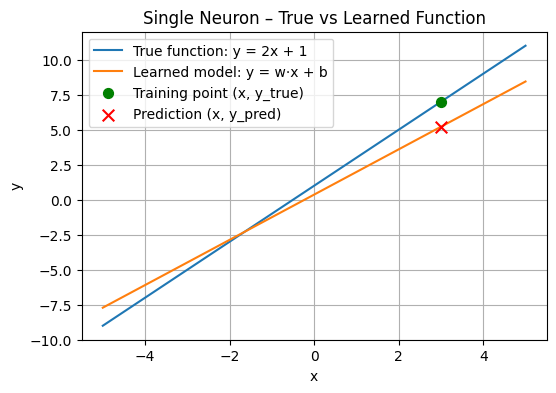

In [13]:
# -----------------------------
# Training data (1 sample)
# -----------------------------
x_train = torch.tensor([3.0]).unsqueeze(1)
y_true = 2 * x_train + 1

# -----------------------------
# Model
# -----------------------------
class SingleNeuron(nn.Module):
    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.randn(1))
        self.b = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        return self.w * x + self.b

net = SingleNeuron()

loss_fn = nn.MSELoss()
optimizer = optim.SGD(net.parameters(), lr=0.01)

# -----------------------------
# Training
# -----------------------------
epochs = 5
for _ in range(epochs):
    y_pred = net(x_train)
    loss = loss_fn(y_pred, y_true)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f"Learned parameters: w={net.w.item():.4f}, b={net.b.item():.4f}")

# -----------------------------
# Visualization
# -----------------------------
x_plot = torch.linspace(-5, 5, 200).unsqueeze(1)

with torch.no_grad():
    y_true_line = 2 * x_plot + 1
    y_model_line = net(x_plot)
    y_pred_point = net(x_train)

plt.figure(figsize=(6, 4))

# True function
plt.plot(x_plot.numpy(), y_true_line.numpy(),
         label="True function: y = 2x + 1")

# Learned function
plt.plot(x_plot.numpy(), y_model_line.numpy(),
         label="Learned model: y = w·x + b")

# Training point (true value)
plt.scatter(x_train.numpy(), y_true.numpy(),
            color="green", s=50, zorder=5,
            label="Training point (x, y_true)")

# Prediction point
plt.scatter(x_train.numpy(), y_pred_point.numpy(),
            color="red", marker="x", s=70, zorder=6,
            label="Prediction (x, y_pred)")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Single Neuron – True vs Learned Function")
plt.legend()
plt.grid(True)
plt.show()

### 1 - ერთი sample vs Dataset

* ერთი მნიშვნელობის ნაცვლად გამოიყენეთ მონაცემების სვეტი:

```python
x_train = torch.linspace(-5, 5, 50).unsqueeze(1)
```

* გააწვრთენით იგივე მოდელი და დააკვირდით შედეგებს.

#### რატომ არის training უფრო სტაბილური?

* ერთი sample-ის შემთხვევაში

  * გრადიენტი ეფუძნება მხოლოდ ერთ წერტილს
  * შედეგი ძლიერ არის დამოკიდებული შემთხვევით ინიციალიზაციაზე
  * Loss შეიძლება მერყეობდეს

* მრავალი sample-ის შემთხვევაში

  * გრადიენტი არის შეცდომების საშუალო
  * ხმაური ერთმანეთის გავლენას ამცირებს
  * სწავლის მიმართულება უფრო საიმედო და სტაბილურია

---

### 2 - სამიზნე ფუნქციის შეცვლა

* შეცვალეთ სამიზნე ფუნქცია

$$
y_{\text{true}} = 2x + 1
$$

შემდეგი ფუნქციით:

$$
y_{\text{true}} = -3x + 5
$$

* თავიდან გაუშვით სწავლების ნაწილი.

    * რა მნიშვნელობებზე კონვერგირდება w და b?
    * როგორ იცვლება w-ის ნიშანი სწავლებისას? (დადებითი → უარყოფითი, თუ თავიდანვე უარყოფითია?)

---

### 3 - Learning Rate-ის გავლენა

* მოსინჯეთ სხვადასხვა learning rate მნიშვნელობები:

```python
lr = 0.1
lr = 0.01
lr = 0.001
```

* როდის ხდება სწავლა არასტაბილური (divergence)?
* როდის არის სწავლა ძალიან ნელი?
* რომელი learning rate იძლევა საუკეთესო ბალანსს სისწრაფესა და სტაბილურობას შორის?